In [17]:
from functools import partial
import matplotlib.pyplot as plt
import numpy as np
from superfv import AdvectionSolver, ics

In [18]:
common = dict(
    ic = partial(ics.square, rho_min=0.0, rho_max=1.0, vx=2, vy=1, P=np.nan),
    nx = 16,
    ny = 16,
    p = 3,
    use_MOOD=True,
    use_NAD=True,
    rtol=1e-5,
    PAD_bounds={"rho": (0.0, 1.0)},
    use_global_bounds=False,
    use_SED=False,
    detect_closing_troubles=False,
    MUSCL_limiter="pp2d",
    CFL=0.4,
)
sim0 = AdvectionSolver(**(common | dict(use_MOOD=False)))
sim1 = AdvectionSolver(**common, fallback_cascade="muscl", max_revs=1)
sim2 = AdvectionSolver(**common, fallback_cascade="muscl0", max_revs=2)
sim3 = AdvectionSolver(**common, fallback_cascade="muscl0", max_revs=3)

sim0.take_n_steps(1, time_integrator="forward_euler")
sim1.take_n_steps(1, time_integrator="forward_euler")
sim2.take_n_steps(1, time_integrator="forward_euler")
sim3.take_n_steps(1, time_integrator="forward_euler")

SuperFV: step 1/1 | dt=8.33e-03 | rho_min=-1.11e-01 | E_cons=nan | wall=5.58e-04s (done)
SuperFV: step 1/1 | dt=8.33e-03 | rho_min=-2.60e-04 | E_cons=nan | wall=1.93e-03s (done)
SuperFV: step 1/1 | dt=8.33e-03 | rho_min=0.00e+00 | E_cons=nan | wall=2.35e-03s (done)
SuperFV: step 1/1 | dt=8.33e-03 | rho_min=0.00e+00 | E_cons=nan | wall=2.46e-03s (done)


In [19]:
plt.rcParams['font.size'] = 14
plt.rcParams['text.usetex'] = True

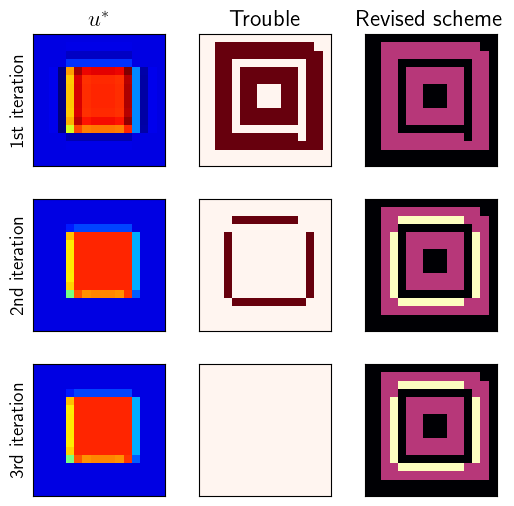

In [20]:
fig, axs = plt.subplots(3, 3, figsize=(6, 6), sharex=True, sharey=True)
axs[0, 0].set_xticks([])
axs[0, 0].set_yticks([])
for ax in axs.flat:
    ax.set_box_aspect(1)

axs[0, 0].set_title(r"$u^{*}$")
axs[0, 1].set_title("Trouble")
axs[0, 2].set_title("Revised scheme")

axs[0, 0].set_ylabel("1st iteration")
axs[1, 0].set_ylabel("2nd iteration")
axs[2, 0].set_ylabel("3rd iteration")

def get_xy(sim):
    return sim.mesh.faces[0], sim.mesh.faces[1]

def plot(ax, sim, item, i=-1, nan_mask = False, **style):
    x, y = get_xy(sim)
    snapshot = sim.snapshot_history[i]

    match item:
        case "rho":
            z = snapshot.u[sim.idx("rho"), :, :, 0]
            if nan_mask:
                z = np.where(np.logical_and(z >= 0.0, z <= 1.0), z, np.nan)
        case "trouble":
            z = snapshot.troubles[0, :, :, 0]
            if nan_mask:
                z = np.where(z, z, np.nan)
        case "cascade":
            z = snapshot.cascade_idx[0, :, :, 0]
        case _:
            raise ValueError(f"Unknown item {item}")

    ax.pcolormesh(x, y, z.T, **style)

rho_min = min(sim.snapshot_history[1].u[sim.idx("rho")].min() for sim in [sim0, sim1, sim2])
rho_max = max(sim.snapshot_history[1].u[sim.idx("rho")].max() for sim in [sim0, sim1, sim2])

plot(axs[0, 0], sim0, i=1, item="rho", cmap="jet", shading="flat", vmin=rho_min, vmax=rho_max)
plot(axs[0, 1], sim1, i=1, item="trouble", cmap="Reds", shading="flat", vmin=0.0, vmax=1.0)
plot(axs[0, 2], sim1, i=1, item="cascade", cmap="magma", shading="flat", vmin=0.0, vmax=2.0)

plot(axs[1, 0], sim1, i=1, item="rho", cmap="jet", shading="flat", vmin=rho_min, vmax=rho_max)
plot(axs[1, 1], sim2, i=1, item="trouble", cmap="Reds", shading="flat", vmin=0.0, vmax=1.0)
plot(axs[1, 2], sim2, i=1, item="cascade", cmap="magma", shading="flat", vmin=0.0, vmax=2.0)

plot(axs[2, 0], sim2, i=1, item="rho", cmap="jet", shading="flat", vmin=rho_min, vmax=rho_max)
plot(axs[2, 1], sim3, i=1, item="trouble", cmap="Reds", shading="flat", vmin=0.0, vmax=1.0)
plot(axs[2, 2], sim3, i=1, item="cascade", cmap="magma", shading="flat", vmin=0.0, vmax=2.0)

plt.subplots_adjust(wspace=0.25, hspace=0.25)